# Does the model still work without angina?

111426 - Dora's point: the model leans heavily on `HadAngina` (the BRFSS question "Ever told you had angina or coronary heart disease?"). What happens if we retrain without it???

3 XGBoost models, all with the original hyperparameters from `xgboost_model.ipynb`, the same split and the same encoding: all 42 features, without `HadAngina`, and without `HadAngina` and `ChestScan` (chest scans often follow a heart diagnosis, too). Each gets its own 80%-recall threshold chosen on validation, the operating point our team agreed on. (the test set is scored once). 

**Summary**
- **Angina carries a lot of real signal.** Without it, test PR-AUC drops from 0.434 to 0.262 and ROC-AUC from 0.891 to 0.845. Dropping `ChestScan` as well changes almost nothing.
- **Removing it doesn't help people without angina.** Inside that group both models rank risk equally well (ROC-AUC 0.815 vs 0.815). The original model already does as well for them as a model that never sees angina.
- **At 80% overall recall** the no-angina model catches more cases without angina (70% vs 55%) and fewer with it (86% vs 100%). To do that it flags 29% of people instead of 22%, at 15% precision instead of 21%.
- **Without angina the model uses the same features**, just with bigger shares (age, chest scan, general health, sex). There's no hidden alternative signal.

**End Thought:** keep angina in-  Catching more cases without angina is a threshold question (a lower cutoff), with the same trade-off of flagging more people.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 42
DATA_PATH = "../Data/heart_2022_with_nans.csv"
TARGET = "HadHeartAttack"
TARGET_RECALL = 0.80          # the operating point the team agreed on
OUT_DIR = Path("../outputs/xgb_no_angina")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("xgboost", xgb.__version__)

xgboost 3.2.0


### 1. Data

Identical to `xgboost_model.ipynb`: same filter, 60/20/20 stratified split with seed 42, same encoding and engineered columns.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df[TARGET].notna()].reset_index(drop=True)
y = (df[TARGET] == "Yes").astype(int)
X_raw = df.drop(columns=[TARGET])
X_tmp, X_test_raw, y_tmp, y_test = train_test_split(X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
del df, X_raw, X_tmp, y_tmp

YES_NO = ["PhysicalActivities", "HadAngina", "HadStroke", "HadAsthma", "HadSkinCancer",
          "HadCOPD", "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis",
          "DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
          "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands",
          "ChestScan", "AlcoholDrinkers", "HIVTesting", "FluVaxLast12",
          "PneumoVaxEver", "HighRiskLastYear"]
ORDINAL = {
    "GeneralHealth": {"Poor": 0, "Fair": 1, "Good": 2, "Very good": 3, "Excellent": 4},
    "RemovedTeeth": {"None of them": 0, "1 to 5": 1, "6 or more, but not all": 2, "All": 3},
    "LastCheckupTime": {
        "Within past year (anytime less than 12 months ago)": 0,
        "Within past 2 years (1 year but less than 2 years ago)": 1,
        "Within past 5 years (2 years but less than 5 years ago)": 2,
        "5 or more years ago": 3},
    "SmokerStatus": {
        "Never smoked": 0, "Former smoker": 1,
        "Current smoker - now smokes some days": 2,
        "Current smoker - now smokes every day": 3},
    "ECigaretteUsage": {
        "Never used e-cigarettes in my entire life": 0, "Not at all (right now)": 1,
        "Use them some days": 2, "Use them every day": 3},
}
CAT_COLS = ["HadDiabetes", "RaceEthnicityCategory", "TetanusLast10Tdap", "CovidPos"]
CHRONIC = ["HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
           "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis"]
DISABILITY = ["DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
              "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands"]


def encode(raw):
    # identical to encode(raw, engineer=True) in xgboost_model.ipynb
    X = raw.drop(columns=["State"]).copy()
    for c in YES_NO:
        X[c] = raw[c].map({"Yes": 1.0, "No": 0.0})
    X["Sex"] = raw["Sex"].map({"Male": 1.0, "Female": 0.0})
    for c, order in ORDINAL.items():
        X[c] = raw[c].map(order)
    X["AgeCategory"] = raw["AgeCategory"].str.extract(r"(\d+)", expand=False).astype(float)
    X["BMI"] = raw["BMI"].fillna(raw["WeightInKilograms"] / raw["HeightInMeters"] ** 2)
    X["chronic_count"] = X[CHRONIC].sum(axis=1)
    X["diabetes_yes"] = (raw["HadDiabetes"] == "Yes").astype(float)
    X["disability_count"] = X[DISABILITY].sum(axis=1)
    X["n_missing"] = raw.isna().sum(axis=1)
    return X


X_train, X_val, X_test = (encode(r) for r in (X_train_raw, X_val_raw, X_test_raw))
levels = {c: sorted(X_train[c].dropna().unique()) for c in CAT_COLS}
for X in (X_train, X_val, X_test):
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c], categories=levels[c])
print(X_train.shape, X_val.shape, X_test.shape)

(265239, 42) (88414, 42) (88414, 42)


### 2. Three models, same settings

Same hyperparameters for all three, so the only difference is the features. (Re-tuning without angina is possible, but the tuning experiments in `xgboost_improved.ipynb` moved PR-AUC by about 0.001, far less than the gap here.)

In [3]:
PARAMS = {"colsample_bytree": 0.6373608964950321, "gamma": 1.1224868516954023,
          "learning_rate": 0.04326278471926905, "max_depth": 5, "min_child_weight": 1,
          "reg_alpha": 0.1191646709003216, "reg_lambda": 8.592225728587435, "subsample": 0.7975182385457563}

VARIANTS = {"all 42 features (original)": [],
            "without HadAngina": ["HadAngina"],
            "without HadAngina and ChestScan": ["HadAngina", "ChestScan"]}


def threshold_for_recall(y_true, p, target):
    prec, rec, thr = precision_recall_curve(y_true, p)
    return float(thr[rec[:-1] >= target].max())   # highest cutoff that still reaches the target recall


models, cols_used, p_val, p_test, thresholds = {}, {}, {}, {}, {}
for name, drop in VARIANTS.items():
    cols = [c for c in X_train.columns if c not in drop]
    m = xgb.XGBClassifier(n_estimators=2000, early_stopping_rounds=50, eval_metric="auc", tree_method="hist",
                          enable_categorical=True, random_state=SEED, n_jobs=-1, **PARAMS)
    m.fit(X_train[cols], y_train, eval_set=[(X_val[cols], y_val)], verbose=False)
    models[name], cols_used[name] = m, cols
    p_val[name] = m.predict_proba(X_val[cols])[:, 1]
    thresholds[name] = threshold_for_recall(y_val, p_val[name], TARGET_RECALL)
    print(f"{name:<34} {m.best_iteration + 1} trees | validation PR-AUC {average_precision_score(y_val, p_val[name]):.4f}"
          f" | {TARGET_RECALL:.0%}-recall threshold {thresholds[name]:.4f}")

all 42 features (original)         181 trees | validation PR-AUC 0.4298 | 80%-recall threshold 0.0553


without HadAngina                  230 trees | validation PR-AUC 0.2730 | 80%-recall threshold 0.0577


without HadAngina and ChestScan    222 trees | validation PR-AUC 0.2670 | 80%-recall threshold 0.0581


### 3. Test set (scored once)

"Inside the no-angina group" = the 82,355 test rows that answered No to angina: how well each model ranks risk among them.

In [4]:
y_t = y_test.to_numpy()
angina = X_test["HadAngina"].to_numpy()
no_ang, yes_ang = angina == 0, angina == 1

rows = {}
for name in VARIANTS:
    p = p_test[name] = models[name].predict_proba(X_test[cols_used[name]])[:, 1]
    flag = p >= thresholds[name]
    rows[name] = {"PR-AUC": average_precision_score(y_t, p), "ROC-AUC": roc_auc_score(y_t, p),
                  "threshold": thresholds[name], "recall": flag[y_t == 1].mean(), "precision": y_t[flag].mean(),
                  "flagged %": 100 * flag.mean(),
                  "recall, cases with angina": flag[yes_ang & (y_t == 1)].mean(),
                  "recall, cases without angina": flag[no_ang & (y_t == 1)].mean(),
                  "ROC-AUC inside no-angina group": roc_auc_score(y_t[no_ang], p[no_ang]),
                  "PR-AUC inside no-angina group": average_precision_score(y_t[no_ang], p[no_ang])}
results = pd.DataFrame(rows).T
results.to_csv(OUT_DIR / "no_angina_results_test.csv")
results.round(4)

,PR-AUC,ROC-AUC,threshold,recall,precision,flagged %,"recall, cases with angina","recall, cases without angina",ROC-AUC inside no-angina group,PR-AUC inside no-angina group
all 42 features (original),0.4335,0.8906,0.0553,0.7869,0.2077,21.5260,1.0000,0.5463,0.8151,0.1184
without HadAngina,0.2616,0.8445,0.0577,0.7891,0.1547,28.9807,0.8610,0.7041,0.8152,0.1191
without HadAngina and ChestScan,0.2563,0.8395,0.0581,0.7841,0.1525,29.2024,0.8544,0.7028,0.8091,0.1157


In [5]:
# how sure are we about the drop? 300 paired bootstrap resamples of the test rows
a, b = p_test["all 42 features (original)"], p_test["without HadAngina"]
rng = np.random.RandomState(SEED)
drops = []
for _ in range(300):
    i = rng.randint(0, len(y_t), len(y_t))
    drops.append([average_precision_score(y_t[i], a[i]) - average_precision_score(y_t[i], b[i]),
                  roc_auc_score(y_t[i], a[i]) - roc_auc_score(y_t[i], b[i])])
drops = np.array(drops)
for k, metric in enumerate(["PR-AUC", "ROC-AUC"]):
    lo, hi = np.percentile(drops[:, k], [2.5, 97.5])
    print(f"{metric} lost without angina: {drops[:, k].mean():.4f}  (95% CI {lo:.4f} to {hi:.4f})")

PR-AUC lost without angina: 0.1722  (95% CI 0.1620 to 0.1827)
ROC-AUC lost without angina: 0.0461  (95% CI 0.0432 to 0.0495)


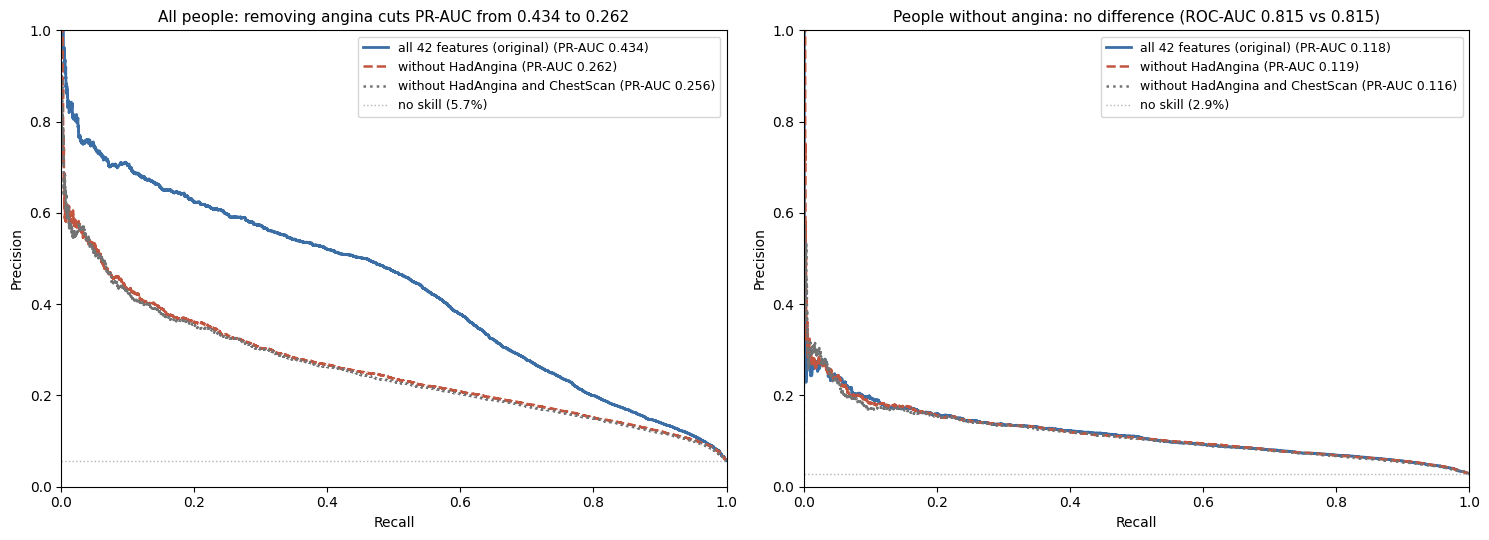

In [6]:
styles = {"all 42 features (original)": dict(color="#3b6ea5", ls="-", lw=2),
          "without HadAngina": dict(color="#c2553f", ls="--", lw=1.8),
          "without HadAngina and ChestScan": dict(color="0.45", ls=":", lw=1.8)}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, mask, label in [(axes[0], np.ones_like(y_t, dtype=bool), "All test rows"),
                        (axes[1], no_ang, "Only people without angina")]:
    for name in VARIANTS:
        prec, rec, _ = precision_recall_curve(y_t[mask], p_test[name][mask])
        ax.plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y_t[mask], p_test[name][mask]):.3f})",
                **styles[name])
    ax.axhline(y_t[mask].mean(), color="0.7", ls=":", lw=1, label=f"no skill ({y_t[mask].mean():.1%})")
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=9, loc="upper right")
orig, noang = "all 42 features (original)", "without HadAngina"
axes[0].set_title(f"All people: removing angina cuts PR-AUC from {results.loc[orig, 'PR-AUC']:.3f} "
                  f"to {results.loc[noang, 'PR-AUC']:.3f}", fontsize=11)
axes[1].set_title(f"People without angina: no difference (ROC-AUC {results.loc[orig, 'ROC-AUC inside no-angina group']:.3f}"
                  f" vs {results.loc[noang, 'ROC-AUC inside no-angina group']:.3f})", fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / "pr_curves_with_without_angina.png", dpi=200, bbox_inches="tight")
plt.show()

### 4. What the model uses without angina

Share of total mean |SHAP| on the test set (same method as `shap_analysis.ipynb`), top 10 features of each model.

In [7]:
def shap_share(name):
    m, cols = models[name], cols_used[name]
    contribs = m.get_booster().predict(xgb.DMatrix(X_test[cols], enable_categorical=True),
                                       pred_contribs=True, iteration_range=(0, m.best_iteration + 1))
    imp = pd.Series(np.abs(contribs[:, :-1]).mean(axis=0), index=cols)
    return (100 * imp / imp.sum()).sort_values(ascending=False)


share_orig, share_noang = shap_share(orig), shap_share(noang)
top = share_noang.head(10)
pd.DataFrame({"share without angina %": top, "share in original %": share_orig.reindex(top.index)}).round(1)

,share without angina %,share in original %
AgeCategory,21.799999,16.4
ChestScan,12.500000,10.2
GeneralHealth,10.300000,7.2
Sex,10.200000,7.4
RemovedTeeth,4.900000,4.5
HadStroke,4.500000,4.0
SmokerStatus,4.000000,3.2
HadDiabetes,3.100000,3.0
chronic_count,2.600000,1.7
AlcoholDrinkers,2.400000,2.0


The no-angina model spreads angina's weight over the same features the original already used: age goes from 16% to 22%, chest scan from 10% to 12.5%, general health and sex from about 7% to 10%. Nothing new takes angina's place, which is why the ranking for people without angina doesn't improve.